## Monitoría SECOP 2 — Beca Avanza

### Red neuronal para clasificación: ¿el contrato va a tener prórroga?

Sigue paso a paso el cuaderno de clase `actd_redes_clasif_dataset_heart_starter.ipynb` (ACTD, clases 15-16):

- Redes densas
- Redes para clasificación
- Procesamiento de datos continuos (Normalizer) y categóricos (Lookup)
- Uso de Datasets para trabajar con datos grandes
- Funciones de activación y pérdida

La variable de respuesta es si el contrato tuvo prórroga (`dias_adicionados > 0`), que es el tipo de ineficiencia que predicen los modelos de VigIA (Salazar, Pérez y Gallego, 2024).

Empecemos importando numpy, pandas, keras, tensorflow

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # para que el modelo acepte texto como entrada
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from sklearn.metrics import roc_auc_score, accuracy_score, recall_score, precision_score
from src import modelos as mdl

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


Carguemos la base de contratos unida con procesos. Es la que exporta la aplicación en modo VigIA: trae `dias_adicionados` de la tabla de contratos y `precio_base` de la tabla de procesos. Aquí son la Agencia Nacional de Tierras, la UNP y la Agencia para la Reincorporación, firmados desde 2022.

In [2]:
RUTA = '../data/processed/base_prorrogas_ANT_UNP_ARN.csv'
base = pd.read_csv(RUTA, low_memory=False)
base.shape

(60608, 22)

**Este paso no está en el cuaderno de clase y es el más importante.** Varias columnas de SECOP 2 se actualizan después de firmar el contrato, y con ellas dentro el modelo "adivinaría" con información del futuro. `mdl.preparar` deja solo variables que se conocen al firmar y solo contratos cuyo fin pactado ya pasó (uno en ejecución todavía puede recibir su prórroga).

In [3]:
pd.Series(mdl.VARIABLES_PROHIBIDAS, name='por qué se deja fuera').to_frame()

,por qué se deja fuera
estado_contrato,cambia a «Modificado» justamente cuando hay pr...
valor_del_contrato,se actualiza con las adiciones en valor
dias_adicionados,es la respuesta
ultima_actualizacion,fecha de la última modificación
valor_pagado,se conoce durante la ejecución
valor_facturado,se conoce durante la ejecución
valor_pendiente_de_pago,se conoce durante la ejecución
valor_pendiente_de_ejecucion,se conoce durante la ejecución
liquidaci_n,se conoce al final


In [4]:
df = mdl.preparar(base, fecha_corte='2026-10-26')
df.head()

,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,mes_de_firma,fecha_de_firma,prorroga
0,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.862131,222.0,1.0,0.0,5,2025-05-22 09:36:59.532,0
1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.236380,72.0,2.0,0.0,10,2025-10-17 16:49:49.083,0
2,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,Si,Inversión,Distribuido,No,80,7.681241,151.0,3.0,0.0,1,2024-01-27 18:49:12.752,0
3,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.534504,125.0,2.0,0.0,4,2025-04-25 15:01:16.809,0
5,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.146433,67.0,1.0,0.0,10,2024-10-24 00:35:05.161,0


Exploremos el tamaño del df

In [5]:
df.shape

(52747, 17)

Proporción de contratos con prórroga. Como en `heart`, la clase está desbalanceada: el accuracy solo no basta.

In [6]:
df['prorroga'].value_counts(normalize=True).round(3)

prorroga
0    0.878
1    0.122
Name: proportion, dtype: float64

Identificamos NAs en los datos

In [7]:
df.isna().sum()

modalidad_de_contratacion             0
tipo_de_contrato                      0
justificacion_modalidad_de            0
nombre_entidad                        0
tipodocproveedor                      0
es_pyme                               0
destino_gasto                         0
origen_de_los_recursos                0
el_contrato_puede_ser_prorrogado      0
segmento_unspsc                       0
log_precio_base                     137
duracion_planeada                    78
dias_firma_a_inicio                  78
respuestas_al_procedimiento         112
mes_de_firma                          0
fecha_de_firma                        0
prorroga                              0
dtype: int64

Definimos listas para las variables categóricas enteras, categóricas string y numéricas.

El mes de firma va como categórica entera, igual que `slope` y `ca` en `heart`: enero y diciembre no están "lejos" en el sentido que importa, así que cada mes lleva su propia columna.

In [8]:
cat_int_feats = ['mes_de_firma']

In [9]:
cat_str_feats = ['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de',
                 'nombre_entidad', 'tipodocproveedor', 'es_pyme', 'destino_gasto',
                 'origen_de_los_recursos', 'el_contrato_puede_ser_prorrogado', 'segmento_unspsc']

In [10]:
num_feats = ['log_precio_base', 'duracion_planeada', 'dias_firma_a_inicio', 'respuestas_al_procedimiento']

Agregamos las listas de categorías

In [11]:
feats_ordered = cat_int_feats + cat_str_feats + num_feats

Guardamos la fecha de firma (la usamos para separar) y reordenamos el dataframe de acuerdo con el tipo de variable

In [12]:
fecha_firma = df['fecha_de_firma']
df = df[feats_ordered + ['prorroga']]
df.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,prorroga
0,5,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.862131,222.0,1.0,0.0,0
1,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.236380,72.0,2.0,0.0,0
2,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,Si,Inversión,Distribuido,No,80,7.681241,151.0,3.0,0.0,0
3,4,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.534504,125.0,2.0,0.0,0
5,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.146433,67.0,1.0,0.0,0


Separamos los datos en entrenamiento, validación y prueba.

**Única diferencia con el cuaderno de clase:** la prueba no es un 20% al azar, sino los contratos firmados desde 2025. Así se usaría el modelo de verdad: entrenado con el pasado para anticipar contratos nuevos. La validación sí sale como en clase, el 20% del entrenamiento con `random_state=100`.

In [13]:
test = df[fecha_firma >= '2025-01-01']
train = df.drop(test.index)

In [14]:
val = train.sample(frac=0.2, random_state=100)

In [15]:
train = train.drop(val.index)

In [16]:
for nombre, d in [('Entrenamiento', train), ('Validación', val), ('Prueba', test)]:
    print(f'{nombre:14s} n = {len(d):6d}   con prórroga = {d.prorroga.mean():.1%}')

Entrenamiento  n =  24103   con prórroga = 8.2%
Validación     n =   6026   con prórroga = 8.1%
Prueba         n =  22618   con prórroga = 17.6%


Los datos de `heart` no tenían vacíos; estos sí. Llenamos las numéricas con la mediana **de entrenamiento**, para no usar nada de la prueba, y ajustamos los tipos que espera cada entrada.

In [17]:
medianas = train[num_feats].median()

def ajustar_tipos(d):
    d = d.copy()
    d[num_feats] = d[num_feats].fillna(medianas).astype('float32')
    d[cat_int_feats] = d[cat_int_feats].astype('int64')
    d[cat_str_feats] = d[cat_str_feats].astype(str)
    d['prorroga'] = d['prorroga'].astype('int64')
    return d

train, val, test = ajustar_tipos(train), ajustar_tipos(val), ajustar_tipos(test)

Calculamos estadísticas de cada variable numérica

In [18]:
train[num_feats].describe()

,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento
count,24103.000000,24103.000000,24103.000000,24103.000000
mean,7.631592,195.999207,3.239057,0.069825
std,0.463216,104.400162,5.113501,0.922557
min,5.845098,0.000000,-3.000000,0.000000
25%,7.407408,124.000000,1.000000,0.000000
50%,7.579783,167.000000,2.000000,0.000000
75%,7.763628,279.000000,4.000000,0.000000
max,12.414877,1371.000000,256.000000,47.000000


Función para convertir de dataframe (pandas) a dataset (tensorflow), separando características y etiquetas. Solo el de entrenamiento se baraja; validación y prueba quedan en orden para que las predicciones coincidan con las etiquetas al calcular las métricas.

In [19]:
def dataframe_to_dataset(dataframe, shuffle=True):
    dataframe = dataframe.copy()
    labels = dataframe.pop("prorroga")
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=100)
    return ds

In [20]:
train_ds = dataframe_to_dataset(train)
val_ds = dataframe_to_dataset(val, shuffle=False)
test_ds = dataframe_to_dataset(test, shuffle=False)

Ejemplo de cómo queda el tf.dataset

In [21]:
for x, y in train_ds.take(1):
    print("Input:", {k: v.numpy() for k, v in x.items()})
    print("Target:", y.numpy())

Input: {'mes_de_firma': np.int64(5), 'modalidad_de_contratacion': b'Contrataci\xc3\xb3n directa', 'tipo_de_contrato': b'Prestaci\xc3\xb3n de servicios', 'justificacion_modalidad_de': b'Servicios profesionales y apoyo a la gesti\xc3\xb3n', 'nombre_entidad': b'AGENCIA NACIONAL DE TIERRAS - ANT', 'tipodocproveedor': b'C\xc3\xa9dula de Ciudadan\xc3\xada', 'es_pyme': b'No', 'destino_gasto': b'Inversi\xc3\xb3n', 'origen_de_los_recursos': b'Distribuido', 'el_contrato_puede_ser_prorrogado': b'No', 'segmento_unspsc': b'80', 'log_precio_base': np.float32(7.6623044), 'duracion_planeada': np.float32(210.0), 'dias_firma_a_inicio': np.float32(5.0), 'respuestas_al_procedimiento': np.float32(0.0)}
Target: 0


Agrupamos los datos de entrenamiento, validación y prueba en lotes

In [22]:
batch_size = 32
train_ds = train_ds.batch(batch_size)
test_ds = test_ds.batch(batch_size)
val_ds = val_ds.batch(batch_size)

Función para codificar variables numéricas (Keras docs)

In [23]:
def encode_numerical_feature(feature, name, dataset):
    # Crea capa de normalización para este feature
    normalizer = keras.layers.Normalization()

    # Prepara el dataset para considerar únicamente la feature de interés (name)
    feature_ds = dataset.map(lambda x, y: x[name]) # selecciona variable
    feature_ds = feature_ds.map(lambda x: tf.expand_dims(x, -1)) # deja el tensor de una dimensión

    # Aprende las estadísticas de los datos (media, varianza)
    normalizer.adapt(feature_ds)

    # Aplica la normalización a la variable
    encoded_feature = normalizer(feature)
    return encoded_feature

Función para codificar variables categóricas (Keras docs)

In [24]:
def encode_categorical_feature(feature, name, dataset, is_string):
    lookup_class = keras.layers.StringLookup if is_string else keras.layers.IntegerLookup
    # Crea una capa Lookup para retornar variables 0/1 (dummies)
    # lookup: busca el valor correspondiente de la variable categórica
    lookup = lookup_class(output_mode="binary")

    # Prepara el dataset para considerar únicamente la feature de interés (name)
    feature_ds = dataset.map(lambda x, y: x[name]) # selecciona variable
    feature_ds = feature_ds.map(lambda x: tf.expand_dims(x, -1)) # deja el tensor de una dimensión

    # Aprende el conjunto de posibles valores que toma la variable categórica y asigna enteros
    lookup.adapt(feature_ds)

    # Aplica la conversión de categorías a enteros
    encoded_feature = lookup(feature)
    return encoded_feature

Creamos una lista de inputs para el modelo, de acuerdo con cada tipo de variable

In [25]:
keras.utils.set_random_seed(0)

inputs = []
for i in cat_int_feats:
  inputs.append(keras.Input(shape=(1,), name=i, dtype="int64"))

In [26]:
for i in cat_str_feats:
  inputs.append(keras.Input(shape=(1,), name=i, dtype="string"))

In [27]:
for i in num_feats:
  inputs.append(keras.Input(shape=(1,), name=i))

Creamos una lista de variables codificadas/normalizadas de acuerdo con su tipo, empleando las funciones de codificación/normalización

In [28]:
feats_encoded=[]

In [29]:
for i,feat in enumerate(cat_int_feats):
  feats_encoded.append(
      encode_categorical_feature(inputs[i], feat, train_ds, False)
  )

In [30]:
len_feats = len(feats_encoded)
for i,feat in enumerate(cat_str_feats):
  feats_encoded.append(
      encode_categorical_feature(inputs[len_feats+i], feat, train_ds, True)
  )

In [31]:
len_feats = len(feats_encoded)
for i,feat in enumerate(num_feats):
  feats_encoded.append(
      encode_numerical_feature(inputs[len_feats+i], feat, train_ds)
  )

Creamos una capa concatenando todas las variables codificadas

In [32]:
all_feats = keras.layers.concatenate(feats_encoded)
print('Columnas de entrada a la red después de codificar:', all_feats.shape[-1])

Columnas de entrada a la red después de codificar: 129


Agregamos una capa densa con 32 neuronas y función de activación relu

In [33]:
model_layers = keras.layers.Dense(32, activation='relu')(all_feats)

Agregamos la capa de salida con 1 neurona (probabilidad de que el contrato tenga prórroga) y función de activación sigmoide

In [34]:
model_layers = keras.layers.Dense(1, activation='sigmoid')(model_layers)

Creamos el modelo con las capas ya creadas y las variables de entrada

In [35]:
model = keras.Model(inputs, model_layers)

Compilamos el modelo, definiendo optimizador, función de pérdida y métricas adicionales a capturar

In [36]:
model.compile(optimizer='adam', loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.Recall(name='recall')])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mes_de_firma        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ modalidad_de_contr… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tipo_de_contrato    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ justificacion_moda… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ nombre_entidad      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tipodocproveedor    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ es_pyme             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ destino_gasto       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ origen_de_los_recu… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ el_contrato_puede_… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ segmento_unspsc     │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_precio_base     │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duracion_planeada   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dias_firma_a_inicio │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ respuestas_al_proc… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ integer_lookup      │ (None, 13)        │          0 │ mes_de_firma[0][… │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup       │ (None, 11)        │          0 │ modalidad_de_con

 Total params: 4,205 (16.44 KB)

 Trainable params: 4,193 (16.38 KB)

 Non-trainable params: 12 (64.00 B)

In [37]:
try:
    keras.utils.plot_model(model, show_shapes=True, rankdir="LR")
except Exception as e:
    print('plot_model no disponible (requiere graphviz):', e)

plot_model no disponible (requiere graphviz): You must install pydot (`pip install pydot`) for `plot_model` to work.


Entrenamos el modelo con los datos en el formato tf.Dataset

In [38]:
history = model.fit(train_ds, epochs=50, validation_data=val_ds, verbose=0)
print('Pérdida final  entrenamiento: %.4f   validación: %.4f' %
      (history.history['loss'][-1], history.history['val_loss'][-1]))

Pérdida final  entrenamiento: 0.1391   validación: 0.1702


Pérdida de entrenamiento y de validación por época. Si la de validación sube mientras la de entrenamiento baja, la red está memorizando.

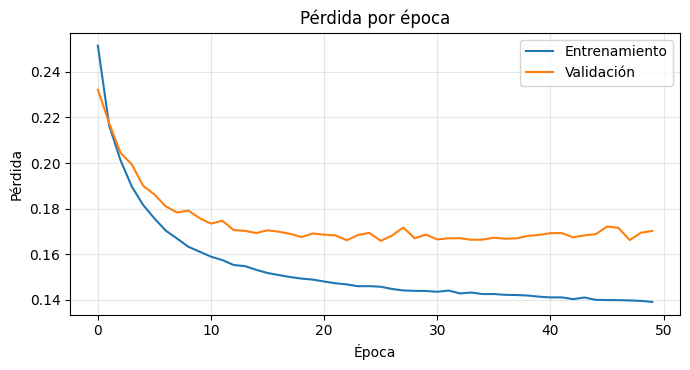

Mínima pérdida de validación: 0.1659 en la época 26; al final: 0.1702


In [39]:
h = history.history
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(h['loss'], label='Entrenamiento'); ax.plot(h['val_loss'], label='Validación')
ax.set_xlabel('Época'); ax.set_ylabel('Pérdida'); ax.set_title('Pérdida por época'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
vl = np.array(h['val_loss'])
print(f'Mínima pérdida de validación: {vl.min():.4f} en la época {vl.argmin() + 1}; al final: {vl[-1]:.4f}')

Evaluamos en prueba (contratos firmados desde 2025)

In [40]:
model.evaluate(test_ds, verbose=0, return_dict=True)

{'accuracy': 0.8336280584335327,
 'loss': 0.4288973808288574,
 'recall': 0.3111949563026428}

Métricas en prueba. Además de las de clase, el **acierto en el 10% más riesgoso**: de los contratos que el modelo pondría primero en la fila de revisión, cuántos de verdad tuvieron prórroga. Es la que importa para priorizar la vigilancia, que es para lo que existe VigIA.

In [41]:
y_test = test['prorroga'].values
prob_red = model.predict(test_ds, verbose=0).ravel()

def metricas(y_true, y_prob, umbral=0.5, fraccion=0.10):
    y_pred = (y_prob >= umbral).astype(int)
    n_top = int(round(len(y_true) * fraccion))
    top = np.argsort(-y_prob, kind='stable')[:n_top]
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, y_prob),
        'Acierto en el 10% más riesgoso': y_true[top].mean() if np.ptp(y_prob) > 0 else y_true.mean(),
    }

pd.Series(metricas(y_test, prob_red)).round(3).to_frame('Red neuronal')

,Red neuronal
Accuracy,0.834
Precision,0.547
Recall,0.311
AUC,0.872
Acierto en el 10% más riesgoso,0.547


### Comparación con la línea base y la regresión logística

Con los mismos datos de entrenamiento (entrenamiento + validación, porque la logística no necesita validación) y la misma prueba:

- **Línea base**: decir siempre que no habrá prórroga.
- **Regresión logística**: el modelo clásico; si la red no la supera, no aporta.

In [42]:
X_tr = pd.concat([train, val])[feats_ordered]
y_tr = pd.concat([train, val])['prorroga']
logistica = mdl.logistica(cat_int_feats, cat_str_feats, num_feats).fit(X_tr, y_tr)
prob_log = logistica.predict_proba(test[feats_ordered])[:, 1]

comparacion = pd.DataFrame({
    'Línea base': metricas(y_test, np.zeros(len(y_test))),
    'Regresión logística': metricas(y_test, prob_log),
    'Red neuronal': metricas(y_test, prob_red),
}).T.round(3)
comparacion

,Accuracy,Precision,Recall,AUC,Acierto en el 10% más riesgoso
Línea base,0.824,0.000,0.000,0.500,0.176
Regresión logística,0.783,0.445,0.945,0.920,0.724
Red neuronal,0.834,0.547,0.311,0.872,0.547


¿En qué se fija cada modelo? Revolvemos una variable a la vez y medimos cuánto cae el AUC. Si no cae, el modelo no la estaba usando.

In [43]:
class RedComoModelo:
    # para que la red responda predict_proba igual que la logística
    def predict_proba(self, X):
        ds = tf.data.Dataset.from_tensor_slices(dict(X)).batch(256)
        p = model.predict(ds, verbose=0).ravel()
        return np.column_stack([1 - p, p])

muestra = test.sample(5000, random_state=0)
importancias = pd.DataFrame({
    'Regresión logística': mdl.importancia(logistica, muestra[feats_ordered], muestra['prorroga']),
    'Red neuronal': mdl.importancia(RedComoModelo(), muestra[feats_ordered], muestra['prorroga']),
}).round(2).sort_values('Red neuronal', ascending=False)
importancias.rename(index=mdl.NOMBRES)

,Regresión logística,Red neuronal
Duración pactada,21.61,32.83
Entidad,7.23,3.49
Mes de firma,14.28,2.81
Precio base,2.29,1.90
Funcionamiento o inversión,6.11,1.75
Modalidad,0.42,0.44
Causal invocada,0.62,0.34
Segmento del bien o servicio,0.23,0.34
Persona natural o jurídica,0.50,0.28
Días de la firma al inicio,0.01,0.25


### Lectura de los resultados

- **La red aprende.** En prueba (contratos firmados desde 2025) tiene AUC de 0,87, frente a 0,50 de la línea base. En el 10% de contratos que pone como más riesgosos, el 55% tuvo prórroga; revisando al azar sería el 18%.
- **La regresión logística es mejor** en las dos medidas que no dependen del umbral: AUC de 0,92 y 72% de acierto en el 10% más riesgoso. Con estos datos, la red no aporta sobre el modelo lineal.
- **La red empieza a memorizar desde la época 26.** Ahí la pérdida de validación toca su mínimo y después sube un poco, mientras la de entrenamiento sigue bajando. Es el mismo patrón del modelo base de `heart`.
- **Con umbral 0,5 la red solo detecta el 31% de las prórrogas** (recall). La logística detecta el 95% porque se entrenó con pesos de clase; la red no, igual que el modelo base del cuaderno de clase. Por eso la comparación se hace con el AUC y el acierto en el 10% más riesgoso, que no dependen del umbral.
- **Las dos se fijan sobre todo en la duración pactada.** Los contratos pactados para terminar en septiembre u octubre se prorrogan mucho más que los de diciembre: es la práctica de extender la planta de contratistas hasta fin de año. Es una prórroga administrativa, no el retraso de entrega que mide VigIA.